In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

In [2]:
df_initial=pd.read_excel("Code Datasets.xlsx", sheet_name="BDI & TCE")

df=df_initial[["Quarter", "TCE ($)", "BDI_AVG"]]
df.columns = ['Quarter', 'TCE', 'BDI']

df = df.dropna().reset_index(drop=True)

df.describe().round(2)

,TCE,BDI
count,50.00,50.00
mean,15055.74,1455.40
std,6783.21,729.32
min,4331.00,358.33
25%,10567.75,986.08
50%,14027.00,1282.00
75%,18443.75,1831.67
max,37406.00,4197.00


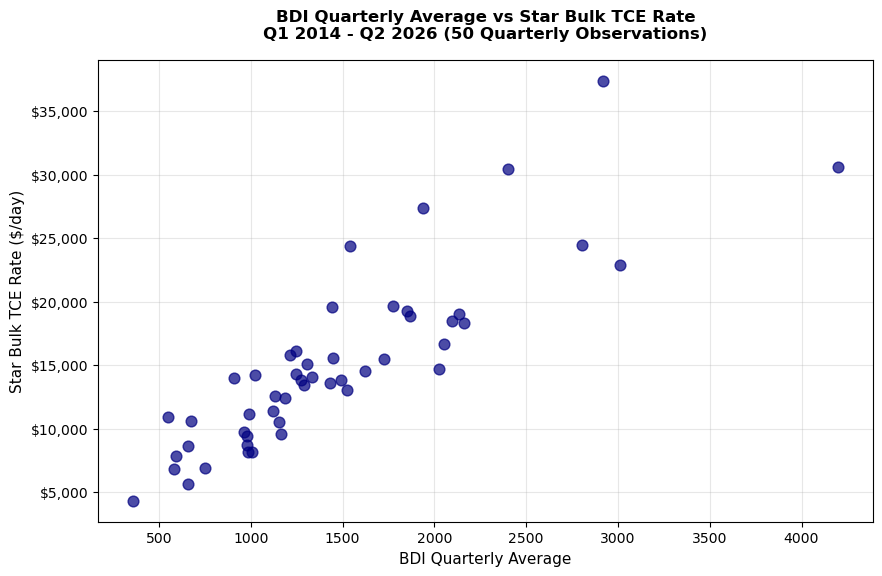

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(df['BDI'], df['TCE'],
           color='navy', alpha=0.7, s=60, zorder=3)

ax.set_title('BDI Quarterly Average vs Star Bulk TCE Rate\n'
             'Q1 2014 - Q2 2026 (50 Quarterly Observations)',
             fontsize=12, fontweight='bold', pad=15)

ax.set_xlabel('BDI Quarterly Average', fontsize=11)
ax.set_ylabel('Star Bulk TCE Rate ($/day)', fontsize=11)
ax.grid(alpha=0.3)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

plt.savefig('BDI_TCE_Scatter.png', dpi=300, bbox_inches='tight')
plt.show()

In [4]:
X = sm.add_constant(df['BDI']) 
y = df['TCE']

model = sm.OLS(y, X)
results = model.fit()

print(results.summary())

alpha = results.params['const']
beta = results.params['BDI']
r_squared = results.rsquared
p_value_beta = results.pvalues['BDI']
p_value_alpha = results.pvalues['const']
t_stat_beta = results.tvalues['BDI']
n_obs = int(results.nobs)
f_stat = results.fvalue
p_value_f = results.f_pvalue

print("KEY REGRESSION RESULTS FOR THESIS")
print(f"Intercept (α):          {alpha:,.2f}")
print(f"BDI Coefficient (β):    {beta:.4f}")
print(f"R-squared:              {r_squared:.4f}")
print(f"t-statistic (β):        {t_stat_beta:.4f}")
print(f"p-value (β):            {p_value_beta:.6f}")
print(f"p-value (α):            {p_value_alpha:.6f}")
print(f"F-statistic:            {f_stat:.4f}")
print(f"p-value (F):            {p_value_f:.6f}")
print(f"Observations:           {n_obs}")

dw = durbin_watson(results.resid)
print(f"Durbin-Watson:          {dw:.4f}")
print("(DW close to 2.0 = no autocorrelation)")

bp_test = het_breuschpagan(results.resid, results.model.exog)
print(f"\nBreusch-Pagan Test:")
print(f"  LM Statistic: {bp_test[0]:.4f}")
print(f"  p-value:      {bp_test[1]:.4f}")
print("  (p > 0.05 = no heteroskedasticity)")

print("HYPOTHESIS 1 TEST RESULT")
if p_value_beta < 0.01:
    print(f"p-value = {p_value_beta:.6f} < 0.01")
    print("H1 ACCEPTED at 1% significance level.")
    print("BDI is a statistically significant predictor of TCE.")
elif p_value_beta < 0.05:
    print(f"p-value = {p_value_beta:.6f} < 0.05")
    print("H1 ACCEPTED at 5% significance level.")
else:
    print(f"p-value = {p_value_beta:.6f} > 0.05")
    print("H1 REJECTED.")

                            OLS Regression Results                            
Dep. Variable:                    TCE   R-squared:                       0.738
Model:                            OLS   Adj. R-squared:                  0.733
Method:                 Least Squares   F-statistic:                     135.5
Date:                Fri, 06 Nov 2026   Prob (F-statistic):           1.40e-15
Time:                        00:27:24   Log-Likelihood:                -478.03
No. Observations:                  50   AIC:                             960.1
Df Residuals:                      48   BIC:                             963.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       3424.3709   1115.595      3.070      0.0

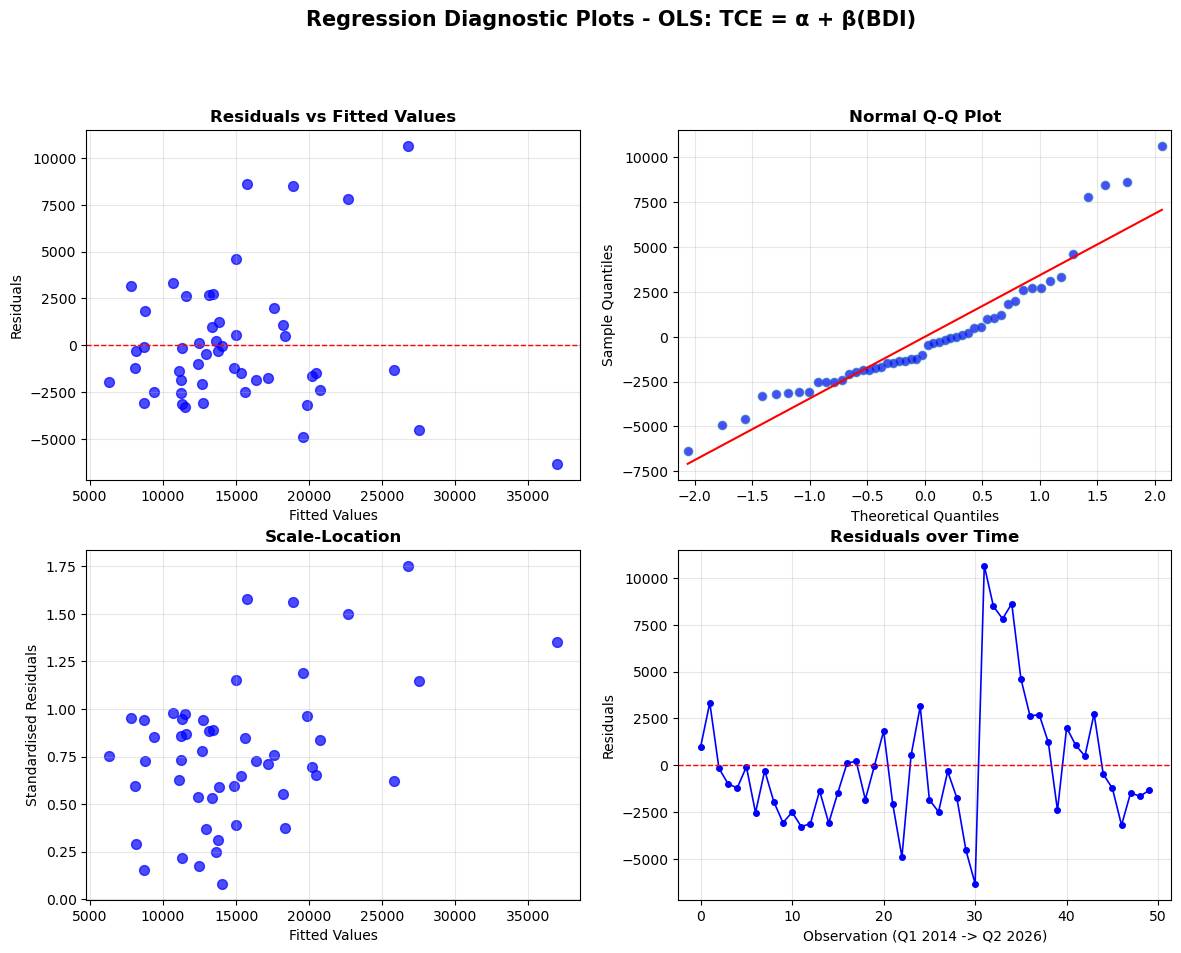

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fitted_vals = results.fittedvalues
residuals = results.resid
std_residuals = residuals / residuals.std()

axes[0,0].scatter(fitted_vals, residuals,
                  color='blue', alpha=0.7, s=50)
axes[0,0].axhline(y=0, color='red', linewidth=1, linestyle='--')
axes[0,0].set_title('Residuals vs Fitted Values', fontweight='bold')
axes[0,0].set_xlabel('Fitted Values')
axes[0,0].set_ylabel('Residuals')
axes[0,0].grid(alpha=0.3)

sm.qqplot(residuals, line='s', ax=axes[0,1],
          markerfacecolor='blue', alpha=0.7)
axes[0,1].set_title('Normal Q-Q Plot', fontweight='bold')
axes[0,1].grid(alpha=0.3)

axes[1,0].scatter(fitted_vals, np.sqrt(np.abs(std_residuals)),
                  color='blue', alpha=0.7, s=50)
axes[1,0].set_title('Scale-Location', fontweight='bold')
axes[1,0].set_xlabel('Fitted Values')
axes[1,0].set_ylabel('Standardised Residuals')
axes[1,0].grid(alpha=0.3)

axes[1,1].plot(range(len(residuals)), residuals,
               color='blue', linewidth=1.2, marker='o',
               markersize=4)
axes[1,1].axhline(y=0, color='red', linewidth=1, linestyle='--')
axes[1,1].set_title('Residuals over Time', fontweight='bold')
axes[1,1].set_xlabel('Observation (Q1 2014 -> Q2 2026)')
axes[1,1].set_ylabel('Residuals')
axes[1,1].grid(alpha=0.3)

plt.suptitle('Regression Diagnostic Plots - OLS: TCE = α + β(BDI)',
             fontsize=15, fontweight='bold', y=1)

plt.savefig('Regression_Diagnostics.png', dpi=300, bbox_inches='tight')

plt.show()

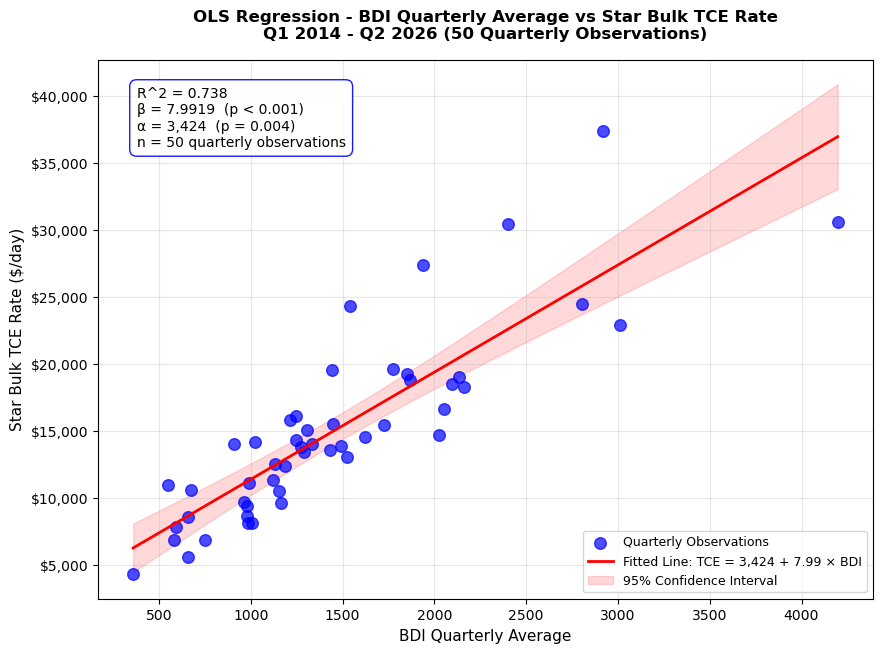

In [6]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(df['BDI'], df['TCE'],
           color='blue', alpha=0.7, s=70,
           label='Quarterly Observations', zorder=3)

bdi_range = np.linspace(df['BDI'].min(), df['BDI'].max(), 200)
tce_fitted = alpha + beta * bdi_range

ax.plot(bdi_range, tce_fitted,
        color='red', linewidth=2,
        label=f'Fitted Line: TCE = {alpha:,.0f} + {beta:.2f} × BDI',
        zorder=4)

pred_df = pd.DataFrame({'const': 1, 'BDI': bdi_range})
predictions = results.get_prediction(pred_df)
ci = predictions.conf_int(alpha=0.05)

ax.fill_between(bdi_range, ci[:, 0], ci[:, 1],
                alpha=0.15, color='red',
                label='95% Confidence Interval')

stats_text = (f'R^2 = {r_squared:.3f}\n'
              f'β = {beta:.4f}  (p < 0.001)\n'
              f'α = {alpha:,.0f}  (p = 0.004)\n'
              f'n = {n_obs} quarterly observations')

ax.text(0.05, 0.95, stats_text,
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment='top',
        bbox=dict(boxstyle='round,pad=0.5',
                  facecolor='white',
                  edgecolor='blue',
                  alpha=0.9))

ax.set_title('OLS Regression - BDI Quarterly Average vs Star Bulk TCE Rate\n'
             'Q1 2014 - Q2 2026 (50 Quarterly Observations)',
             fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('BDI Quarterly Average', fontsize=11)
ax.set_ylabel('Star Bulk TCE Rate ($/day)', fontsize=11)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))
ax.legend(fontsize=9, loc='lower right')
ax.grid(alpha=0.3)

plt.savefig('Regression_Fitted_Line.png', dpi=300, bbox_inches='tight')

plt.show()

In [7]:
arima_df = pd.read_excel("ARIMA_Quarterly_Forecast.xlsx", index_col=0)
print(arima_df.to_string())

tce_projections = pd.DataFrame(index=arima_df.index)

for scenario in ['Bear', 'Base', 'Bull']:
    tce_projections[f'TCE_{scenario}'] = (
        alpha + beta * arima_df[scenario]
    ).round(0).astype(int)

print("\nProjected TCE Rates ($/day) by Scenario:")
print(tce_projections.to_string())

print("\nScenario Summary:")
for scenario in ['Bear', 'Base', 'Bull']:
    col = f'TCE_{scenario}'
    print(f"  {scenario}: min ${tce_projections[col].min():,}  "
          f"max ${tce_projections[col].max():,}  "
          f"avg ${tce_projections[col].mean():,.0f}")


         Bear  Base  Bull
Quarter                  
2026 Q4  2540  3229  3917
2027 Q1  1922  2858  3794
2027 Q2  1627  2663  3699
2027 Q3  1467  2561  3654
2027 Q4  1373  2507  3640
2028 Q1  1313  2478  3643
2028 Q2  1269  2463  3657
2028 Q3  1235  2455  3675

Projected TCE Rates ($/day) by Scenario:
         TCE_Bear  TCE_Base  TCE_Bull
Quarter                              
2026 Q4     23724     29230     34729
2027 Q1     18785     26265     33746
2027 Q2     16427     24707     32986
2027 Q3     15148     23892     32627
2027 Q4     14397     23460     32515
2028 Q1     13918     23228     32539
2028 Q2     13566     23108     32651
2028 Q3     13294     23044     32794

Scenario Summary:
  Bear: min $13,294  max $23,724  avg $16,157
  Base: min $23,044  max $29,230  avg $24,617
  Bull: min $32,515  max $34,729  avg $33,073


In [8]:
lr_bdi = {'Bear': 1200, 'Base': 1800, 'Bull': 2200}

y1_quarters = ['2027 Q1','2027 Q2','2027 Q3','2027 Q4']
y1_tce = {s: tce_projections.loc[y1_quarters, f'TCE_{s}'].mean()
          for s in ['Bear','Base','Bull']}

y2_arima_q = ['2028 Q1','2028 Q2','2028 Q3']

y2_tce = {}
for s in ['Bear','Base','Bull']:
    arima_end_bdi = arima_df.loc['2028 Q3', s]
    q4_bdi = arima_end_bdi + 0.25 * (lr_bdi[s] - arima_end_bdi)
    q4_tce = alpha + beta * q4_bdi
    arima_avg = tce_projections.loc[y2_arima_q, f'TCE_{s}'].mean()
    y2_tce[s] = (arima_avg * 3 + q4_tce) / 4

reversion_weights = {
    'Year 3 (2029)': 0.50,
    'Year 4 (2030)': 0.75,
    'Year 5 (2031)': 1.00
}

start_bdi = {s: float(arima_df.loc['2028 Q3', s])
             for s in ['Bear','Base','Bull']}

yr3_5_tce = {}
for label, weight in reversion_weights.items():
    yr3_5_tce[label] = {}
    for s in ['Bear','Base','Bull']:
        reverted_bdi = start_bdi[s] + weight * (lr_bdi[s] - start_bdi[s])
        yr3_5_tce[label][s] = alpha + beta * reverted_bdi

annual_tce = pd.DataFrame({
    'Year':       ['Year 1 (2027)', 'Year 2 (2028)',
                   'Year 3 (2029)', 'Year 4 (2030)', 'Year 5 (2031)'],
    'TCE_Bear':   [y1_tce['Bear'],  y2_tce['Bear'],
                   yr3_5_tce['Year 3 (2029)']['Bear'],
                   yr3_5_tce['Year 4 (2030)']['Bear'],
                   yr3_5_tce['Year 5 (2031)']['Bear']],
    'TCE_Base':   [y1_tce['Base'],  y2_tce['Base'],
                   yr3_5_tce['Year 3 (2029)']['Base'],
                   yr3_5_tce['Year 4 (2030)']['Base'],
                   yr3_5_tce['Year 5 (2031)']['Base']],
    'TCE_Bull':   [y1_tce['Bull'],  y2_tce['Bull'],
                   yr3_5_tce['Year 3 (2029)']['Bull'],
                   yr3_5_tce['Year 4 (2030)']['Bull'],
                   yr3_5_tce['Year 5 (2031)']['Bull']],
}).set_index('Year')

annual_tce = annual_tce.round(0).astype(int)

print("Annual Average TCE Rate Projections ($/day) - Five-Year Horizon:")
print(annual_tce.to_string())

print(f"\nRegression equation applied: TCE = {alpha:,.0f} + {beta:.4f} × BDI")
print(f"\nLong-run BDI mean reversion targets:")
for s, v in lr_bdi.items():
    lr_tce = int(alpha + beta * v)
    print(f"  {s}: BDI {v:,} -> TCE ${lr_tce:,}/day")


Annual Average TCE Rate Projections ($/day) - Five-Year Horizon:
               TCE_Bear  TCE_Base  TCE_Bull
Year                                       
Year 1 (2027)     16189     24581     32968
Year 2 (2028)     13501     22779     31958
Year 3 (2029)     13154     20427     26900
Year 4 (2030)     13085     19118     23953
Year 5 (2031)     13015     17810     21006

Regression equation applied: TCE = 3,424 + 7.9919 × BDI

Long-run BDI mean reversion targets:
  Bear: BDI 1,200 -> TCE $13,014/day
  Base: BDI 1,800 -> TCE $17,809/day
  Bull: BDI 2,200 -> TCE $21,006/day


In [9]:
with pd.ExcelWriter("TCE_Annual_Projections.xlsx", engine='openpyxl') as writer:

    annual_tce.to_excel(writer, sheet_name='Annual TCE Projections')
    
    tce_projections.to_excel(writer, sheet_name='Quarterly TCE (ARIMA)')
    
    lr_summary = pd.DataFrame({
        'Scenario': ['Bear', 'Base', 'Bull'],
        'Long-Run BDI Target': [lr_bdi[s] for s in ['Bear','Base','Bull']],
        'Long-Run TCE ($/day)': [int(alpha + beta * lr_bdi[s])
                                  for s in ['Bear','Base','Bull']]
    }).set_index('Scenario')
    lr_summary.to_excel(writer, sheet_name='Long-Run Targets')

    reg_ref = pd.DataFrame({
        'Parameter': ['Intercept (α)', 'BDI Coefficient (β)',
                      'R-squared', 'Observations'],
        'Value': [round(alpha, 2), round(beta, 4),
                  round(r_squared, 4), n_obs]
    }).set_index('Parameter')
    reg_ref.to_excel(writer, sheet_name='Regression Reference')

print("TCE Annual Projections saved successfully.")


TCE Annual Projections saved successfully.
